# Pose Estimation

YOLOv5 Pose 모델을 사용한 인간 자세 추정

## 1. 개요 및 시스템 구조

### Pose Estimation 기본 개념
Pose Estimation은 이미지나 비디오에서 사람의 신체 관절점(keypoints)을 검출하여 자세를 추정하는 컴퓨터 비전 기술입니다. COCO 포맷의 17개 관절점을 사용하여 인체의 주요 부위(머리, 어깨, 팔꿈치, 손목, 엉덩이, 무릎, 발목)를 검출합니다.

### 전체 처리 파이프라인
1. **이미지 입력**: 원본 이미지 로드
2. **전처리**: 크기 조정, 패딩, 색상 변환
3. **NPU 추론**: DX Runtime을 통한 Pose 모델 실행
4. **후처리**: 복잡한 디코딩, NMS 적용, 관절점 좌표 변환
5. **결과 시각화**: 관절점 및 스켈레톤 그리기

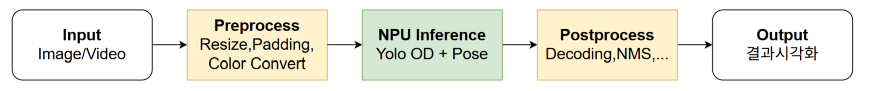

## 2. 모델 설명: YOLOV5Pose640_1.dxnn

### NPU 모델 구조 분석
```bash
$ parse_model -m assets/models/YOLOv5Pose640_1.dxnn 
modelPath: assets/models/YOLOv5Pose640_1.dxnn
.dxnn File Format Version : 6
Compiler Version : 1.40.2
RMapInfo Version : 2.27.1(M-master)
Loaded model infomation
  Task[0] cpu_0, CPU, memory-usage 2457600 bytes (input 1228800, output 1228800)
    inputs
      Im2col_input, UINT8, [1, 640, 640, 3 ], 0
    outputs
      images, UINT8, [1, 640, 1920 ], 0
  Task[0] npu_0, NPU, memory-usage 27936128 bytes (input 1228800, output 131072)
    inputs
      images, UINT8, [1, 640, 1920 ], 0
    outputs
      POSE, POSE, [1, unknown ], 0  
```

### 입출력 텐서 구조
- **입력 텐서**: `images` - UINT8, [1, 640, 640, 3]
- **출력 텐서**: `detections` - FLOAT, [1, unknown]

### 출력 텐서 구조 분석(커스터마이징된 형태)
- **unknown** = 총 예측 박스 수  x info(256)

- **info(256)**:

| Offset | Field | 크기 | 설명 |
|--------|--------|------|------|
| 0-15 | `[x, y, w, h]` | 16B | 바운딩박스 원시값 (float32×4) |
| 16-19 | `[gy, gx, anchor, layer]` | 4B | 그리드 정보 (uint8×4) |
| 20-23 | `objectness` | 4B | 신뢰도 (float32) |
| 24-27 | `class_index` | 4B | 클래스 번호 (uint32) |
| 28-231 | `keypoints` | 204B | 17×3×4 = 204바이트 (float32×51) |
| 232-255 | `reserved` | 24B | 여유 공간 |

### 참고: 표준 YOLOv5 Pose 출력 (일반적 형태):
- **Ultralytics 공식**: `(1, 25200, 56)` 형태 사용
- **키포인트 형식**: `[kx, ky, visibility]` × 17개
- **COCO Pose 포맷**: 17개 관절점 표준
- **56 차원**: `[x, y, w, h, objectness, kx1, ky1, kv1, ..., kx17, ky17, kv17]`
- Pose는 사람에 특화된 정보로 class 정보대신 키포인트 정보 사용 

## 3. 전처리 과정

전처리는 원본 이미지를 모델이 요구하는 형태로 변환하는 단계입니다.

- **이미지 로드**: OpenCV를 사용하여 원본 이미지 로드
- **Letter Boxing**: 640x640 크기로 비율 유지하며 리사이즈 및 패딩
- **색상 변환**: BGR → RGB 변환 (모델 입력 형식에 맞춤)

### 라이브러리 Import 및 초기 설정

- OpenCV, NumPy: 이미지 처리
- Matplotlib: 시각화 (선택적)
- Ultralytics utils: YOLO 관련 유틸리티
- dx_engine: DX Runtime NPU 추론 엔진

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from ultralytics.utils import ops
from dx_engine import InferenceEngine, InferenceOption

### 이미지 시각화 함수 정의

추론 결과와 이미지를 시각화하여 확인하기 위한 함수입니다.

In [2]:
def show_img(img, title="Image", size=(10,10)): # Img 확인을 위한 함수
    plt.figure(figsize=size)
    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

### 이미지 로드 및 기본 정보 확인

원본 이미지를 로드하고 확인합니다.

In [3]:
img_path = "./assets/inputs/play.jpg"
frame = cv2.imread(img_path)
# show_img(frame, "Original Image") # 이미지 확인

### Letter Boxing 전처리

YOLO 모델은 정사각형 입력(640x640)을 요구하므로, 원본 이미지의 비율을 유지하면서 크기를 조정하고 패딩을 추가합니다.

#### 리사이즈 비율 계산

In [4]:
src_shape = frame.shape[:2]
new_shape = (640, 640)

r = min(new_shape[0] / src_shape[0], new_shape[1] / src_shape[1])
ratio = r, r
new_unpad = int(round(src_shape[1] * r)), int(round(src_shape[0] * r))
dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
dw /= 2
dh /= 2

#### 이미지 리사이즈 및 패딩 적용

In [5]:
resized = cv2.resize(frame, new_unpad, interpolation=cv2.INTER_LINEAR)
top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
image_input = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114,114,114))

#show_img(image_input, "Letter Boxed Image") # 전처리된 이미지 확인

#### 색상 변환 (BGR → RGB)

In [6]:
image_input = cv2.cvtColor(image_input, cv2.COLOR_BGR2RGB) # 모델에 맞게 RGB로 변환

pad = (dw, dh)

## 4. NPU 추론과정

DX Runtime의 InferenceEngine을 사용하여 NPU에서 YOLO 모델을 실행합니다.

- **모델 로드**: DX Runtime InferenceEngine으로 .dxnn 모델 로드
- **추론 실행**: NPU에서 추론 수행
- **출력 확인**: [1, unknown, 256] 형태의 결과 텐서 획득

### 모델 로드 및 InferenceEngine 초기화





In [7]:
model_path = "./assets/models/YOLOv5Pose640_1.dxnn"
ie = InferenceEngine(model_path)

DXRT v2.9.5
[  ] -> npu_0 -> [ ]
 InferenceEngine /home/orangepi/ai_examples/assets/models/YOLOv5Pose640_1.dxnn
  Task[0] npu_0, NPU, NPU memory usage 114,738,560 bytes (input 1,228,800 bytes, output 131,072 bytes)
   inputs
     images, UINT8, [1, 640, 1920 ], 0
   outputs
     POSE, POSE, [1, unknown ], 0




### 추론 실행 및 결과 확인

In [8]:
ie_outputs = ie.run([image_input]) # 추론 수행
print("Raw Output Shape:", [o.shape for o in ie_outputs])
print("Raw Output Sample:", ie_outputs[0][0][:5])  # 일부 샘플 출력

Raw Output Shape: [(1, 44, 256)]
Raw Output Sample: [[  0  32   8 ...   0   0   0]
 [  0  31  14 ...   0   0   0]
 [  0 162  70 ...   0   0   0]
 [  0 230 167 ...   0   0   0]
 [  0  96  76 ...   0   0   0]]


## 5. 후처리 과정

Pose 모델의 후처리는 일반 YOLO보다 훨씬 복잡합니다. 바운딩 박스와 17개 관절점을 동시에 디코딩해야 합니다.

- **디코딩**: 바이너리 데이터에서 bbox + 17개 관절점 정보 추출
- **필터링**: 신뢰도 임계값(0.3) 기반 초기 필터링
- **NMS 적용**: IoU 임계값(0.4)으로 중복 박스 제거
- **좌표 변환**: 모델 좌표를 원본 이미지 좌표로 변환

### Sigmoid 함수 및 layer정보 정의

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

kpt_count = 17
layers = [
            {
                "name":"0",
                "stride": 8,
                "anchor_width": [
                    19,
                    44,
                    38
                ],
                "anchor_height": [
                    27,
                    40,
                    94
                ]
            },
            {
                "name":"1",
                "stride": 16,
                "anchor_width": [
                    96,
                    86,
                    180
                ],
                "anchor_height": [
                    68,
                    152,
                    137
                ]
            },
            {
                "name":"2",
                "stride": 32,
                "anchor_width": [
                    140,
                    303,
                    238
                ],
                "anchor_height": [
                    301,
                    264,
                    542
                ]
            },
            {
                "name":"3",
                "stride": 64,
                "anchor_width": [
                    436,
                    739,
                    925
                ],
                "anchor_height": [
                    615,
                    380,
                    792
                ]
            }
        ]

### 디코딩

#### (1) 데이터 추출
- **box** : `data[0:16]` → `[x, y, w, h]`
- **grid 좌표 및 anchor/layer index** : `data[16:20]` → `gy, gx, anchor, layer`.
- **score** : `data[20:24]` → objectness/confidence 값.
- **label** : `data[24:28]` → 클래스 인덱스.
- **kpts** : `data[28:232]` → keypoints (길이 = 17×3 = 51).

#### (2) 레이어(anchor) 정보 적용
- `w, h = anchor width/height`
- `s = stride`  
  stride는 feature map 좌표를 원래 이미지 좌표로 변환할 때 사용.

#### (3) 박스 좌표 디코딩

x_c = (gx - 0.5 + (bx x 2)) x s



y_c = (gy - 0.5 + (by x 2)) x s


w = (bw^2 x 4) x anchor\_w



h = (bh^2 x 4) x anchor\_h


#### (4) Keypoints 디코딩
각 키포인트 `(kx, ky, kc)`에 대해:


px = (kx x 2 - 0.5 + gx) x s


py = (ky x 2 - 0.5 + gy) x s


kc = sigmoid(kc) = 1/(1 + e^{-kc})


→ 최종적으로 `[px, py, kc]`.

#### (5) tensor 구성
- 앞 4개 값 : `[x, y, w, h]`
- 5번째 값 : `score`
- 뒤 51개 값 : 17개 keypoints `(x, y, conf)`.

---

### 최종 출력 구조
한 detection 당 결과는 다음과 같은 벡터로 구성됨:
- `(num_detections,56)`

In [10]:
ie_output0 = ie_outputs[0][0] # (box 후보 수, feature 크기)
num_det = ie_output0.shape[0] # 검출된 박스 수
decoded_tensor = []

for detected_idx in range(num_det):
        tensor = np.zeros((5 + kpt_count * 3), dtype=float)

        data = ie_output0[detected_idx].tobytes()

        box = np.frombuffer(data[0:16], np.float32)
        gy, gx, anchor, layer = np.frombuffer(data[16:20], np.uint8)
        score = np.frombuffer(data[20:24], np.float32).item()
        label = np.frombuffer(data[24:28], np.uint32).item()
        kpts = np.frombuffer(data[28:232], np.float32)

        if layer >= len(layers):
            break

        w = layers[layer]["anchor_width"][anchor]
        h = layers[layer]["anchor_height"][anchor]
        s = layers[layer]["stride"]

        grid = np.array([gx, gy], np.float32)
        anchor_wh = np.array([w, h], np.float32)

        xc = (grid - 0.5 + (box[0:2] * 2)) * s
        wh = (box[2:4] ** 2) * 4 * anchor_wh
        box_decoded = np.concatenate([xc, wh], axis=0)

        kpts_proc = np.zeros_like(kpts)
        for k in range(kpt_count):
            kx, ky, kc = kpts[k*3:(k+1)*3]
            px = (kx * 2.0 - 0.5 + gx) * s
            py = (ky * 2.0 - 0.5 + gy) * s
            kc = sigmoid(kc)
            kpts_proc[k*3:(k+1)*3] = [px, py, kc]

        tensor[:4] = box_decoded
        tensor[4] = score
        tensor[5:5 + kpt_count * 3] = kpts_proc # 설명 추가

        decoded_tensor.append(tensor)

if len(decoded_tensor) == 0:
            decoded_tensor = np.zeros((5 + kpt_count * 3), dtype=float)

decoded_output = np.stack(decoded_tensor)
print("Decoded Tensor Shape:", decoded_output.shape)

Decoded Tensor Shape: (44, 56)


### 필터링

bbox 좌표 변환: 모델 출력은 (cx, cy, w, h) 형태인데, Bounding Box를 그리기 위해선 좌상단 좌표와 우하단 좌표로 변환이 필요합니다.

threshold filtering: 설정한 score_threshold보다 낮은 detection 후보를 제거합니다.

#### *score_threshold 값을 조정하며 image에 box 변화를 확인 가능*

정렬: confidence 높은 순으로 detection 정렬 → NMS 전에 확률 높은 박스부터 확인할 수 있도록 합니다.

### 출력 Output Shape

(N, 56) => N은 Threshold를 통과한 box의 개수입니다.

In [11]:
x = np.squeeze(decoded_output)
score_threshold = 0.3
iou_threshold = 0.4

if x.ndim <= 1 or len(x) == 0:
    print("No detections")


else:
    box = ops.xywh2xyxy(x[..., :4])  # (cx,cy,w,h) → (x1,y1,x2,y2)
    conf = x[:, 4:5]                 # confidence
    j = x[:, 5:6]                    # class

    kpts = x[..., 5:5 + kpt_count * 3] # keypoints

    mask = conf.flatten() > score_threshold
    filtered = np.concatenate((box, conf, j, kpts), axis=1)[mask]

    # confidence 내림차순 정렬
    sorted_indices = np.argsort(-filtered[:, 4])
    x = filtered[sorted_indices]

    print("Shape (box_num, dim):", x.shape)

Shape (box_num, dim): (39, 57)


### NMS (Non-Maximum Suppression) 적용

중복되는 검출 박스를 제거하고 최적의 검출 결과만 유지합니다.

In [12]:
    if len(x) > 0:
        x1, y1, x2, y2, scores, labels = (
            x[:, 0], x[:, 1], x[:, 2], x[:, 3], x[:, 4], x[:, 5]
        )
        keep = []
        idxs = scores.argsort()[::-1]  # 높은 confidence부터 정렬
        while len(idxs) > 0:
            i = idxs[0]
            keep.append(i)
            xx1 = np.maximum(x1[i], x1[idxs[1:]])
            yy1 = np.maximum(y1[i], y1[idxs[1:]])
            xx2 = np.minimum(x2[i], x2[idxs[1:]])
            yy2 = np.minimum(y2[i], y2[idxs[1:]])

            w = np.maximum(0.0, xx2 - xx1)
            h = np.maximum(0.0, yy2 - yy1)
            inter = w * h
            union = ((x2[i]-x1[i]) * (y2[i]-y1[i]) +
                    (x2[idxs[1:]]-x1[idxs[1:]]) * (y2[idxs[1:]]-y1[idxs[1:]]) - inter)
            iou = inter / (union + 1e-6)

            idxs = idxs[1:][iou <= iou_threshold]
        x = x[keep]
    print("Shape After NMS:", x.shape)

Shape After NMS: (2, 57)


### 좌표 변환 (모델 좌표 → 원본 이미지 좌표)

- 전처리 과정에서 입력 이미지를 모델 크기(예: 640x640)에 맞췄기 때문에 원본 이미지 크기에 맞게 좌표를 변환합니다.

#### Box 보정 방식
- pad(좌우/상하 여백 크기)와 ratio(resize 배율)를 이용해 **원래 좌표계로 복구** 합니다.  
- 변환 과정은 padding을 빼주고 resize 배율로 나누어 원본 크기에 맞추는 방식.  

#### Keypoints 보정 방식
- confidence 값이 충분히 높은 keypoint만 원래 좌표로 복구하고,  
  낮은 값은 무시하거나 특정 값(-1 등)으로 처리하여 잘못된 점이 표시되지 않도록 합니다.

In [13]:
    h, w = frame.shape[:2]
    x1 = np.clip(((x[:, 0] - pad[0]) / ratio[0]).astype(int), 0, w - 1)
    y1 = np.clip(((x[:, 1] - pad[1]) / ratio[1]).astype(int), 0, h - 1)
    x2 = np.clip(((x[:, 2] - pad[0]) / ratio[0]).astype(int), 0, w - 1)
    y2 = np.clip(((x[:, 3] - pad[1]) / ratio[1]).astype(int), 0, h - 1)
    x[:, 0:4] = np.stack([x1, y1, x2, y2], axis=1)

    kpts = x[:, 6:].reshape(-1, kpt_count, 3)

    for det_id in range(len(kpts)):
        for k_id, (kx, ky, kc) in enumerate(kpts[det_id]):
            if kc > 0.5:
                px = int((kx - pad[0]) / ratio[0])
                py = int((ky - pad[1]) / ratio[1])
                # clip 해서 이미지 내부로 제한
                px = np.clip(px, 0, w - 1)
                py = np.clip(py, 0, h - 1)
                kpts[det_id, k_id, 0] = px
                kpts[det_id, k_id, 1] = py
            else:
                # 신뢰도 낮으면 좌표를 -1 같은 값으로 처리해도 됨
                kpts[det_id, k_id, 0] = -1
                kpts[det_id, k_id, 1] = -1

            x[:, 6:] = kpts.reshape(len(x), -1)


## 6. 결과 시각화

최종 Pose Estimation 결과를 시각화하고 이미지로 저장합니다.
- **바운딩 박스**: 검출된 사람 주변에 경계 박스 표시
- **관절점 시각화**: 17개 관절점을 빨간 원으로 표시
- **스켈레톤 연결**: 관절점들을 파란 선으로 연결하여 인체 구조 표현
- **이미지 저장**: 최종 결과를 파일로 저장


### 17개 관절점 (COCO Format)
```
0: 코 (nose)
1: 왼쪽 눈 (left_eye)
2: 오른쪽 눈 (right_eye)
3: 왼쪽 귀 (left_ear)
4: 오른쪽 귀 (right_ear)
5: 왼쪽 어깨 (left_shoulder)
6: 오른쪽 어깨 (right_shoulder)
7: 왼쪽 팔꿈치 (left_elbow)
8: 오른쪽 팔꿈치 (right_elbow)
9: 왼쪽 손목 (left_wrist)
10: 오른쪽 손목 (right_wrist)
11: 왼쪽 엉덩이 (left_hip)
12: 오른쪽 엉덩이 (right_hip)
13: 왼쪽 무릎 (left_knee)
14: 오른쪽 무릎 (right_knee)
15: 왼쪽 발목 (left_ankle)
16: 오른쪽 발목 (right_ankle)
```

### 스켈레톤 연결

```
1. 팔 연결
  (5,7): 왼쪽 어깨 → 왼쪽 팔꿈치
  (7,9): 왼쪽 팔꿈치 → 왼쪽 손목
  (6,8): 오른쪽 어깨 → 오른쪽 팔꿈치
  (8,10): 오른쪽 팔꿈치 → 오른쪽 손목

2. 다리 연결
  (11,13): 왼쪽 엉덩이 → 왼쪽 무릎
  (13,15): 왼쪽 무릎 → 왼쪽 발목
  (12,14): 오른쪽 엉덩이 → 오른쪽 무릎
  (14,16): 오른쪽 무릎 → 오른쪽 발목

3. 몸통 연결
  (5,6): 왼쪽 어깨 → 오른쪽 어깨 (어깨선)
  (11,12): 왼쪽 엉덩이 → 오른쪽 엉덩이 (골반선)
  (5,11): 왼쪽 어깨 → 왼쪽 엉덩이 (왼쪽 몸통)
  (6,12): 오른쪽 어깨 → 오른쪽 엉덩이 (오른쪽 몸통)
```

### Pose 시각화 및 스켈레톤 그리기

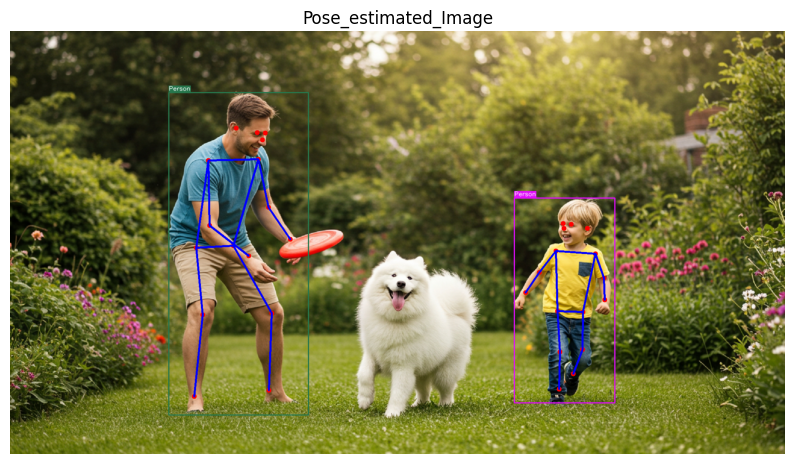

In [14]:
    img_vis = frame.copy()
    for r in x:
        # --- 바운딩 박스 및 클래스 정보 ---
        x1, y1, x2, y2, conf, label = r[:6]
        label = int(label)

        color = tuple(np.random.randint(0, 256, 3).tolist())

        pt1, pt2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(img_vis, pt1, pt2, color, 2)

        text = "Person"
        (tw, th), baseline = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(img_vis, (pt1[0], pt1[1] - th - baseline),
                      (pt1[0] + tw, pt1[1]), color, -1)
        cv2.putText(img_vis, text, (pt1[0], pt1[1] - baseline),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)

        # --- Keypoints 시각화 ---
        kpts = r[6:].reshape(kpt_count, 3)

        # 각 keypoint 점 찍기
        for (kx, ky, kc) in kpts:
            if kc > 0.5:
                px = int(kx)
                py = int(ky)

                if 0 <= px < w and 0 <= py < h:
                    cv2.circle(img_vis, (px, py), 6, (0,0,255), -1)

        # skeleton 연결
        skeleton = [(5,7), (7,9), (6,8), (8,10),
                    (11,13), (13,15), (12,14), (14,16),
                    (5,6), (11,12), (5,11), (6,12)]
        for (p1, p2) in skeleton:
            if kpts[p1][2] > 0.5 and kpts[p2][2] > 0.5:

                p1x, p1y = int(kpts[p1][0]), int(kpts[p1][1])
                p2x, p2y = int(kpts[p2][0]), int(kpts[p2][1])
                # --- IGNORE ---

                cv2.line(img_vis, (p1x, p1y), (p2x, p2y), (255,0,0), 4)

    show_img(img_vis, "Pose_estimated_Image")